# 缩放点积注意力

## 1.必要的函数定义
softmax、缩放点积

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(1)

In [2]:
def softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

In [3]:
def scaled_attention(Q, K, V, mask=None):
    d_K = K.shape[-1]
    scores = Q@K.T / np.sqrt(d_k) # n_q*n_kv
    if mask is not None:
        scores = np.where(mask, scores, -np.inf)
    weights = softmax(scores) # n_q*n_kv
    output = weights@V # n_q*n_v
    return output, weights, scores

## 2.前向

In [4]:
n_q, n_kv, d_k, d_v = 6, 6, 8, 8

Q = np.random.randn(n_q, d_k)
K = np.random.randn(n_kv, d_k)
V = np.random.randn(n_kv, d_v)
print(f"Q:{Q.shape}\nK:{K.shape}\nV:{V.shape}\n")

Q:(6, 8)
K:(6, 8)
V:(6, 8)



In [5]:
output, weights, scores = scaled_attention(Q, K, V)
print("Score:", scores)
print("weights:", weights)
print("output:", output)

Score: [[-0.33896142 -0.96233226  0.5590186  -0.21997407 -0.8261511   0.17689819]
 [ 0.23669105 -0.2471343  -0.90245973  1.29526478 -0.66402842  0.66824766]
 [ 0.07384078  0.75768074 -1.64187716 -0.03069511 -0.01256072 -0.26567843]
 [ 0.00407078 -0.04035654 -0.42308071  0.51558905 -0.05147608 -0.54621678]
 [ 0.17040306  0.0708323  -2.33036879  0.15796711 -0.29508437 -0.28835264]
 [-0.01226176 -0.37734163  0.48276822 -1.18983231  0.48601559 -0.34551298]]
weights: [[0.13501548 0.07238641 0.33141438 0.15207546 0.08294683 0.22616144]
 [0.14782625 0.09112318 0.04731781 0.42607328 0.06005844 0.22760103]
 [0.17570408 0.3481527  0.03159767 0.15826413 0.16116033 0.12512109]
 [0.17242916 0.16493628 0.1124867  0.28758106 0.16311242 0.09945437]
 [0.23613937 0.21375947 0.01936854 0.23322094 0.14825515 0.14925653]
 [0.16652267 0.11559024 0.27318833 0.05129334 0.27407692 0.1193285 ]]
output: [[ 0.16926267 -0.5717859   0.44612278 -0.1501131  -0.51924188 -0.15715728
   0.83653162  0.40786863]
 [-0.0745

## 3.规范化打印

In [6]:
np.set_printoptions(precision=4, suppress=True, linewidth=120)

print("=== Attention Scores (QK^T / sqrt(d_k)) ===\n", scores)
print("\n=== Attention Weights (softmax 后) ===\n", weights)
print("\n每一行权重求和（应为全 1）:", weights.sum(axis=1))

# 手写公式自检
manual = softmax(Q @ K.T / np.sqrt(d_k))
print("与手写公式是否一致:", np.allclose(manual, weights))

=== Attention Scores (QK^T / sqrt(d_k)) ===
 [[-0.339  -0.9623  0.559  -0.22   -0.8262  0.1769]
 [ 0.2367 -0.2471 -0.9025  1.2953 -0.664   0.6682]
 [ 0.0738  0.7577 -1.6419 -0.0307 -0.0126 -0.2657]
 [ 0.0041 -0.0404 -0.4231  0.5156 -0.0515 -0.5462]
 [ 0.1704  0.0708 -2.3304  0.158  -0.2951 -0.2884]
 [-0.0123 -0.3773  0.4828 -1.1898  0.486  -0.3455]]

=== Attention Weights (softmax 后) ===
 [[0.135  0.0724 0.3314 0.1521 0.0829 0.2262]
 [0.1478 0.0911 0.0473 0.4261 0.0601 0.2276]
 [0.1757 0.3482 0.0316 0.1583 0.1612 0.1251]
 [0.1724 0.1649 0.1125 0.2876 0.1631 0.0995]
 [0.2361 0.2138 0.0194 0.2332 0.1483 0.1493]
 [0.1665 0.1156 0.2732 0.0513 0.2741 0.1193]]

每一行权重求和（应为全 1）: [1. 1. 1. 1. 1. 1.]
与手写公式是否一致: True


## 4.热力图

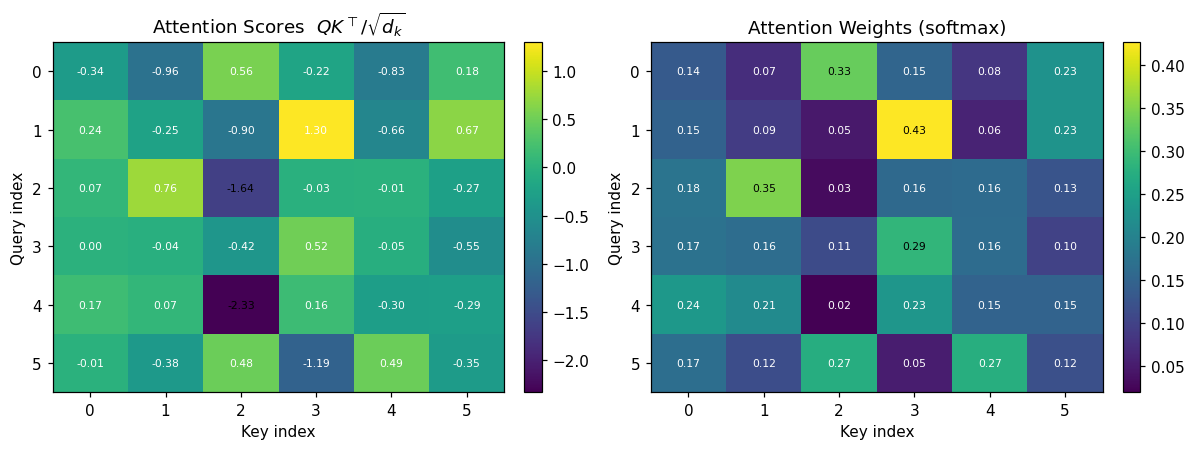

In [7]:
plt.rcParams["figure.dpi"] = 110
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ax, mat, title in zip(
    axes,
    [scores, weights],
    ["Attention Scores  $QK^\\top/\\sqrt{d_k}$", "Attention Weights (softmax)"],
):
    im = ax.imshow(mat, cmap="viridis", aspect="auto")
    ax.set_xlabel("Key index")
    ax.set_ylabel("Query index")
    ax.set_title(title)
    ax.set_xticks(range(mat.shape[1]))
    ax.set_yticks(range(mat.shape[0]))

    # 在每个格子上标注数值
    vmax = np.abs(mat).max()
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(
                j, i, f"{mat[i, j]:.2f}",
                ha="center", va="center", fontsize=7,
                color="white" if abs(mat[i, j]) < 0.65 * vmax else "black",
            )
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 5.多头

### 初始化X，Q，K，V并分成多头

In [8]:
n, d_model, h = 6, 16, 4
d_k = d_v = d_model // h
assert d_model % h == 0,"d_model必须能被h整除"

X = np.random.randn(n, d_model)
print(f"X: {X.shape}  |  h={h}, d_k=d_v={d_k}")

X: (6, 16)  |  h=4, d_k=d_v=4


In [9]:
# 三组投影矩阵，把 d_model 映射到 d_model（再切成 h 个头）
W_q = np.random.randn(d_model, d_model) / np.sqrt(d_model)
W_k = np.random.randn(d_model, d_model) / np.sqrt(d_model)
W_v = np.random.randn(d_model, d_model) / np.sqrt(d_model)
W_o = np.random.randn(d_model, d_model) / np.sqrt(d_model)   # 输出投影

Q = X @ W_q        # (n, d_model)
K = X @ W_k
V = X @ W_v
print("Q/K/V:", Q.shape, K.shape, V.shape)

Q/K/V: (6, 16) (6, 16) (6, 16)


In [10]:
def split_heads(M, h):
    n, d_model = M.shape
    d_k = d_model // h
    return M.reshape(n, h, d_k).transpose(1, 0, 2)

Qh = split_heads(Q, h)   # (h, n, d_k)
Kh = split_heads(K, h)
Vh = split_heads(V, h)

print("拆头后 Qh/Kh/Vh:", Qh.shape, Kh.shape, Vh.shape)

拆头后 Qh/Kh/Vh: (4, 6, 4) (4, 6, 4) (4, 6, 4)


### 逐头做scaled dot-product attention

In [11]:
head_outputs = []   # 每个元素 (n, d_v)
head_weights = []   # 每个元素 (n, n)，用于可视化

for i in range(h):
    out_i, w_i, _ = scaled_attention(Qh[i], Kh[i], Vh[i])
    head_outputs.append(out_i)    # (n, d_v)
    head_weights.append(w_i)      # (n, n)

head_weights = np.stack(head_weights)   # (h, n, n)
print("各头输出:", [o.shape for o in head_outputs])
print("各头权重堆叠:", head_weights.shape)

各头输出: [(6, 4), (6, 4), (6, 4), (6, 4)]
各头权重堆叠: (4, 6, 6)


### 拼接+输出

In [12]:
# (n, d_v) × h  ->  (h, n, d_v)  ->  (n, h, d_v)  ->  (n, d_model)
concat = np.stack(head_outputs, axis=0).transpose(1, 0, 2).reshape(n, d_model)

output = concat @ W_o          # (n, d_model)
print("拼接后:", concat.shape, " 最终输出:", output.shape)

拼接后: (6, 16)  最终输出: (6, 16)


### 可视化

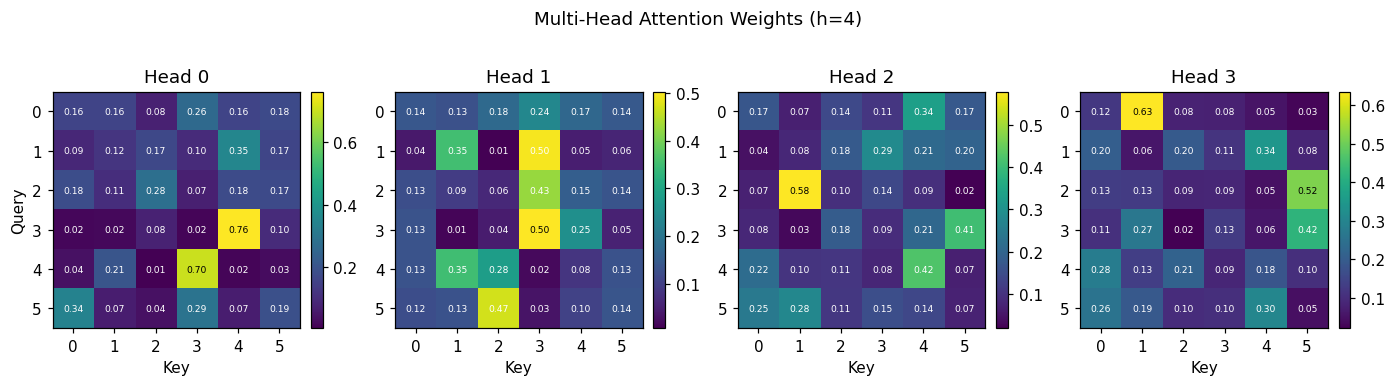

In [13]:
fig, axes = plt.subplots(1, h, figsize=(3.2 * h, 3.4))

for i, ax in enumerate(axes):
    w = head_weights[i]
    im = ax.imshow(w, cmap="viridis", aspect="auto")
    ax.set_title(f"Head {i}")
    ax.set_xlabel("Key")
    ax.set_ylabel("Query" if i == 0 else "")
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    for r in range(n):
        for c in range(n):
            ax.text(c, r, f"{w[r, c]:.2f}", ha="center", va="center",
                    fontsize=6,
                    color="white" if w[r, c] < 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(f"Multi-Head Attention Weights (h={h})", y=1.02)
plt.tight_layout()
plt.show()